# Lab 3: Parameter estimation and Unbiasedness of Estimators

## General comments

- At the beginning of the notebook, provide a work breakdown structure estimating the efforts of each team member.
- Submit **both** the Jupyter notebook source (`.ipynb`) **and** its **HTML** export. Name the files `team_x_lab3.ipynb` and `team_x_lab3.html`, replacing `x` with your team number (e.g. `team_07_lab3.ipynb`). Links to GitHub repositories are **NOT** accepted.
- Before you export, restart the kernel, clear all outputs and run all cells. Ensure that all cells ran correctly and there are no errors.
- All formulas **MUST** be written with LaTeX (\$...\$, \$\$...\$\$). Ensure that they are rendered correctly in your `.ipynb` and `.html` submitted files.
- The **team id number** (`ID`) used in the tasks is the ordinal number of your team in the random selection (you can find it in the assignment on the LMS). You **must** fix the random seed at the beginning of your code so that your calculations are reproducible. Draw all random numbers with `np.random` functions (e.g. `np.random.exponential`), after this seed is set.
- Not complying with these instructions may result in a **point deduction**, regardless of whether your implementation is correct.
- At the defence every team member **MUST** understand all tasks and know all derivations, formulas and results in the notebook. Not knowing any of it will result in a **point deduction**.

## Work breakdown

**Team:** 11

| Team member | Tasks | Share of effort |
|---|---|---|
| _Liubomyr Voskalo_ | _Problem 1 (exponential): derivation of the 4 confidence intervals (a), simulation of coverage and interval lengths (b), conclusions (c)–(d)_ | _≈ 1/3_ |
| _Veronika Parkhomenko_ | _Problem 2 (Poisson): methods 2–4, simulation, comparison, conclusions; Setup (ID, seed)_ | _≈ 1/3_ |
| _Anastasiia Liubenchuk_ | _Problem 3: simulation of variance estimators and their biases (a)–(d), analytical derivation of expectations and proof of unbiasedness (e)–(f), conclusions (g); final Restart & Run All and export_ | _≈ 1/3_ |

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
# All your other imports go here

ID = 11  # TODO: put your team id number here

# Fix the seed once, at the beginning of the notebook, to make all results reproducible.
# Draw all random numbers with np.random functions (e.g. np.random.exponential(scale=theta, size=(n, m)))
np.random.seed(ID)

---

## Part I: Parameter estimation

**Aim:** In Problems 1 and 2 you have to verify that the interval estimates produced by the known rules really contain the parameter with probability equal to the confidence level.

### Problem 1

The expected value of the exponential distribution $\mathscr{E}(\lambda)$ is $1/\lambda$, so the sample mean $\overline{\mathbf{X}}$ is a good point estimate of the parameter $\theta := 1/\lambda$. A confidence interval for $\theta$ can be formed in several different ways:

1. Using the exact distribution of the statistic $2\lambda n\overline{\mathbf{X}}$ (show that it is $\chi^2_{2n}$, then use the quantiles of the latter to get the interval endpoints).

2. Using the normal approximation $\mathscr{N}(\mu, \sigma^2)$ for $\overline{\mathbf{X}}$, with parameters $\mu = \theta$ and $\sigma^2 = s^2/n$, where $s^2 = \theta^2$ is the population variance (the variance of the original distribution $\mathscr{E}(\lambda)$). In other words, form the $Z$-statistic $Z := \sqrt{n}\,(\overline{\mathbf{X}} - \theta)/\theta$ and use the fact that it is approximately standard normal $\mathscr{N}(0, 1)$:

   $$\mathsf{P}\big(|\theta - \overline{\mathbf{X}}| \le z_\beta\, \theta/\sqrt{n}\big) = \mathsf{P}(|Z| \le z_\beta) = 2\beta - 1,$$

   so $\theta$ lies within $\overline{\mathbf{X}} \pm z_\beta\,\theta/\sqrt{n}$ with probability $2\beta - 1$. (Here $z_\beta$ is the $\beta$-quantile of $\mathscr{N}(0, 1)$).

3. The confidence interval constructed above uses the unknown variance $s^2 = \theta^2$, so it is of little use in practice. Instead, solve the double inequality

   $$|\theta - \overline{\mathbf{X}}| \le z_\beta\, \theta/\sqrt{n}$$

   for $\theta$. This gives another confidence interval that does not depend on the unknown parameter.

4. Another, more universal way to remove the dependence on $\theta$ in (2) is to estimate $s$ by the sample standard deviation and approximate $\overline{\mathbf{X}}$ with the Student $t$-distribution (see Ross's textbook on statistics or the lecture notes for details).

**Task:**

   **(a)** Derive confidence intervals for each of the 4 methods above.

   **(b)** For each method, estimate the actual confidence (the fraction of intervals containing $\theta = 1/\lambda$, which should be close to $1-\alpha$) and the interval lengths. Use $\theta = \texttt{ID}/10$, $\alpha = 0.1;\ 0.05;\ 0.01$, and vary the sample size $n$ and the number of repetitions $m$. Choose convenient visualizations (tables, plots against $n$, etc.) to compare all methods at a glance.

   **(c)** Explain how $n$ and $m$ affect the probability that the parameter lies in each of the four random intervals above, and the lengths of these intervals.

   **(d)** Compare all 4 methods: what are the pros and cons of each, which is the best, and in which cases.


#### Solution

Let $X_1,\dots,X_n \sim \mathscr{E}(\lambda)$ i.i.d., $\theta = 1/\lambda$. Then $\mathsf{E}X = \theta$ and $\mathrm{Var}\,X = \theta^2$, so $s^2 = \theta^2$. Throughout, $\beta = 1-\alpha/2$ (so that $2\beta - 1 = 1-\alpha$), $z_\beta$ is the $\beta$-quantile of $\mathscr{N}(0,1)$, $t_{n-1,\beta}$ is the $\beta$-quantile of the Student distribution $t_{n-1}$, and $\chi^2_{k,p}$ is the $p$-quantile of $\chi^2_k$.

**(a) Derivation of the intervals.**

**Method 1 (exact distribution of $2\lambda n\overline{\mathbf X}$).**

*Step 1: $2\lambda X_i \sim \chi^2_2$.* For $Y = 2\lambda X_i$ and $y \ge 0$,
$$\mathsf P(Y \le y) = \mathsf P\Big(X_i \le \frac{y}{2\lambda}\Big) = 1 - e^{-\lambda \cdot y/(2\lambda)} = 1 - e^{-y/2},$$
so $f_Y(y) = \tfrac12 e^{-y/2}$, $y\ge 0$. This is exactly the density of $\chi^2_2$ (the $\chi^2_k$ density $\frac{y^{k/2-1}e^{-y/2}}{2^{k/2}\Gamma(k/2)}$ with $k=2$).

*Step 2: sum of independent $\chi^2_2$.* The moment generating function of $\chi^2_k$ is $M(t) = (1-2t)^{-k/2}$, $t<\tfrac12$. Since the $X_i$ are independent,
$$M_{2\lambda n\overline{\mathbf X}}(t) = M_{\sum_{i=1}^n 2\lambda X_i}(t) = \prod_{i=1}^n (1-2t)^{-1} = (1-2t)^{-2n/2},$$
which is the MGF of $\chi^2_{2n}$. Hence
$$2\lambda n\overline{\mathbf X} = \frac{2n\overline{\mathbf X}}{\theta} \sim \chi^2_{2n}.$$

*Step 3: the interval.* Its distribution does not depend on $\theta$, so
$$\mathsf P\Big(\chi^2_{2n,\alpha/2} \le \frac{2n\overline{\mathbf X}}{\theta} \le \chi^2_{2n,1-\alpha/2}\Big) = 1-\alpha
\quad\Longleftrightarrow\quad
\mathsf P\Big(\frac{2n\overline{\mathbf X}}{\chi^2_{2n,1-\alpha/2}} \le \theta \le \frac{2n\overline{\mathbf X}}{\chi^2_{2n,\alpha/2}}\Big) = 1-\alpha .$$
Interval:
$$\boxed{\;\theta \in \Big[\frac{2n\overline{\mathbf X}}{\chi^2_{2n,1-\alpha/2}},\ \frac{2n\overline{\mathbf X}}{\chi^2_{2n,\alpha/2}}\Big]\;}$$
Its confidence level is **exactly** $1-\alpha$ for every $n$. Length $L_1 = 2n\overline{\mathbf X}\big(\frac{1}{\chi^2_{2n,\alpha/2}} - \frac{1}{\chi^2_{2n,1-\alpha/2}}\big)$, with $\mathsf E L_1 = 2n\theta\big(\frac{1}{\chi^2_{2n,\alpha/2}} - \frac{1}{\chi^2_{2n,1-\alpha/2}}\big)$. The interval is not symmetric around $\overline{\mathbf X}$; like the distribution of $\overline{\mathbf X}$, it is skewed to the right.

**Method 2 (normal approximation, known variance).** By the CLT, $Z = \sqrt n(\overline{\mathbf X}-\theta)/\theta \approx \mathscr N(0,1)$, so $\mathsf P(|Z|\le z_\beta) \approx 2\beta-1 = 1-\alpha$ and
$$\boxed{\;\theta \in \Big[\overline{\mathbf X} - z_\beta\frac{\theta}{\sqrt n},\ \overline{\mathbf X} + z_\beta\frac{\theta}{\sqrt n}\Big]\;}$$
The endpoints contain the unknown $\theta$, so this is not a real confidence interval. We simulate it with the true $\theta$ only as a benchmark. Its length $L_2 = 2z_\beta\theta/\sqrt n$ is deterministic.

*Exact confidence of methods 2 and 3.* Since $n\overline{\mathbf X}/\theta = \sum X_i/\theta \sim \Gamma(n,1)$ (sum of $n$ independent $\mathscr E(1)$), we can compute the actual confidence of method 2 exactly:
$$\mathsf P(|Z|\le z_\beta) = \mathsf P\big(n - z_\beta\sqrt n \le G \le n + z_\beta\sqrt n\big),\qquad G\sim\Gamma(n,1).$$
It does not depend on $\theta$ and tends to $1-\alpha$ as $n\to\infty$. We compare it with the simulation below.

**Method 3 (solving the inequality for $\theta$).** Since $\theta>0$,
$$|\theta-\overline{\mathbf X}| \le z_\beta\frac{\theta}{\sqrt n}
\iff -z_\beta\frac{\theta}{\sqrt n} \le \theta - \overline{\mathbf X} \le z_\beta\frac{\theta}{\sqrt n}
\iff \begin{cases} \theta\big(1 + \frac{z_\beta}{\sqrt n}\big) \ge \overline{\mathbf X},\\ \theta\big(1 - \frac{z_\beta}{\sqrt n}\big) \le \overline{\mathbf X}. \end{cases}$$
If $z_\beta < \sqrt n$, dividing by the positive numbers $1 \pm z_\beta/\sqrt n$ gives
$$\boxed{\;\theta \in \Big[\frac{\overline{\mathbf X}}{1 + z_\beta/\sqrt n},\ \frac{\overline{\mathbf X}}{1 - z_\beta/\sqrt n}\Big]\;}$$
If $z_\beta \ge \sqrt n$, the second inequality holds for every $\theta>0$ and the interval is $\big[\overline{\mathbf X}/(1+z_\beta/\sqrt n),\ +\infty\big)$. For example, this happens for $n=5$, $\alpha=0.01$, where $z_{0.995}\approx 2.576 > \sqrt5 \approx 2.236$.

The interval depends only on $\overline{\mathbf X}$. The transformation is an equivalence, so on the same sample the events "$\theta\in$ interval 2" and "$\theta \in$ interval 3" coincide, and **methods 2 and 3 have identical coverage**. The length is
$$L_3 = \overline{\mathbf X}\,\frac{2z_\beta/\sqrt n}{1 - z_\beta^2/n},\qquad \mathsf E L_3 = \frac{L_2}{1 - z_\beta^2/n} > L_2 ,$$
so it is always longer than interval 2, and much longer when $z_\beta^2/n$ is close to $1$.

**Method 4 (Student $t$).** Replace $s$ by the sample standard deviation $S = \sqrt{\frac{1}{n-1}\sum_{i=1}^n (X_i-\overline{\mathbf X})^2}$ and use $T = \sqrt n(\overline{\mathbf X}-\theta)/S \approx t_{n-1}$. From $\mathsf P(|T| \le t_{n-1,\beta}) \approx 1-\alpha$:
$$\boxed{\;\theta \in \Big[\overline{\mathbf X} - t_{n-1,\beta}\frac{S}{\sqrt n},\ \overline{\mathbf X} + t_{n-1,\beta}\frac{S}{\sqrt n}\Big]\;}$$
$T$ has exactly the $t_{n-1}$ distribution only for normal samples. For the exponential distribution it is only approximate, because $\overline{\mathbf X}$ and $S$ are not independent and the data are strongly skewed. The length $L_4 = 2t_{n-1,\beta}S/\sqrt n$ is random.

**(b) Simulation plan.** We use $\theta = \texttt{ID}/10 = 1.1$ and $\alpha \in\{0.1, 0.05, 0.01\}$. For every $n \in \{5, 10, 20, 30, 50, 100, 200, 500, 1000\}$ we generate $m = 10\,000$ samples of size $n$ with `np.random.exponential`. All four intervals are built on the same samples. For each method we compute:
- the empirical confidence (the fraction of the $m$ intervals that contain $\theta$),
- the mean interval length.

For methods 2 and 3 we also show the exact confidence from the $\Gamma(n,1)$ formula. To see the effect of $m$, we fix $n=10$, $\alpha=0.05$ and repeat the whole experiment $20$ times for each $m \in \{10^2, 10^3, 10^4, 10^5\}$. The spread of the estimates should match the Monte Carlo standard error $\sqrt{p(1-p)/m}$.


=== alpha = 0.1  (nominal confidence 0.9) ===
--- empirical confidence (fraction of intervals containing theta) ---


method,1: exact chi^2,2: normal (true var),3: solve inequality,4: Student t,"exact (2, 3)"
n,,,,,
5,0.8981,0.9209,0.9209,0.8282,0.9218
10,0.8997,0.9110,0.9110,0.8547,0.9113
20,0.9021,0.9047,0.9047,0.8759,0.9057
30,0.9010,0.9040,0.9040,0.8756,0.9038
50,0.8978,0.9014,0.9014,0.8867,0.9023
100,0.9012,0.9020,0.9020,0.8938,0.9011
200,0.8991,0.9007,0.9007,0.8978,0.9006
500,0.9032,0.9038,0.9038,0.8994,0.9002
1000,0.9023,0.9020,0.9020,0.9004,0.9001


--- mean interval length ---


method,1: exact chi^2,2: normal (true var),3: solve inequality,4: Student t
n,,,,
5,2.1918,1.6183,3.5283,1.8123
10,1.3240,1.1443,1.5651,1.1786
20,0.8678,0.8092,0.9327,0.8125
30,0.6923,0.6607,0.7248,0.6622
50,0.5271,0.5118,0.5413,0.5134
100,0.3673,0.3619,0.3721,0.3623
200,0.2579,0.2559,0.2596,0.2561
500,0.1623,0.1618,0.1627,0.1618
1000,0.1146,0.1144,0.1148,0.1145



=== alpha = 0.05  (nominal confidence 0.95) ===
--- empirical confidence (fraction of intervals containing theta) ---


method,1: exact chi^2,2: normal (true var),3: solve inequality,4: Student t,"exact (2, 3)"
n,,,,,
5,0.9488,0.9564,0.9564,0.8769,0.9562
10,0.9501,0.9573,0.9573,0.9015,0.9549
20,0.9516,0.9554,0.9554,0.9227,0.9528
30,0.9506,0.9501,0.9501,0.9261,0.9519
50,0.9483,0.9487,0.9487,0.9354,0.9512
100,0.9516,0.9523,0.9523,0.9437,0.9506
200,0.9490,0.9481,0.9481,0.9471,0.9503
500,0.9509,0.9514,0.9514,0.9498,0.9501
1000,0.9508,0.9511,0.9511,0.9490,0.9501


... (2 outputs left out)


=== alpha = 0.01  (nominal confidence 0.99) ===
--- empirical confidence (fraction of intervals containing theta) ---


method,1: exact chi^2,2: normal (true var),3: solve inequality,4: Student t,"exact (2, 3)"
n,,,,,
5,0.9896,0.9819,0.9819,0.9473,0.9823
10,0.9903,0.9873,0.9873,0.9533,0.9858
20,0.9907,0.9889,0.9889,0.9659,0.9880
30,0.9882,0.9878,0.9878,0.9726,0.9887
50,0.9892,0.9893,0.9893,0.9770,0.9892
100,0.9904,0.9902,0.9902,0.9847,0.9896
200,0.9902,0.9893,0.9893,0.9860,0.9898
500,0.9907,0.9904,0.9904,0.9893,0.9899
1000,0.9915,0.9912,0.9912,0.9903,0.9900


--- mean interval length ---


method,1: exact chi^2,2: normal (true var),3: solve inequality,4: Student t
n,,,,
5,4.6679,2.5343,inf,3.9139
10,2.4037,1.7920,5.3127,2.0895
20,1.4611,1.2671,1.8899,1.3443
30,1.1374,1.0346,1.3258,1.0743
50,0.8494,0.8014,0.9244,0.8207
100,0.5835,0.5667,0.6072,0.5731
200,0.4068,0.4007,0.4148,0.4030
500,0.2549,0.2534,0.2568,0.2538
1000,0.1798,0.1792,0.1804,0.1794


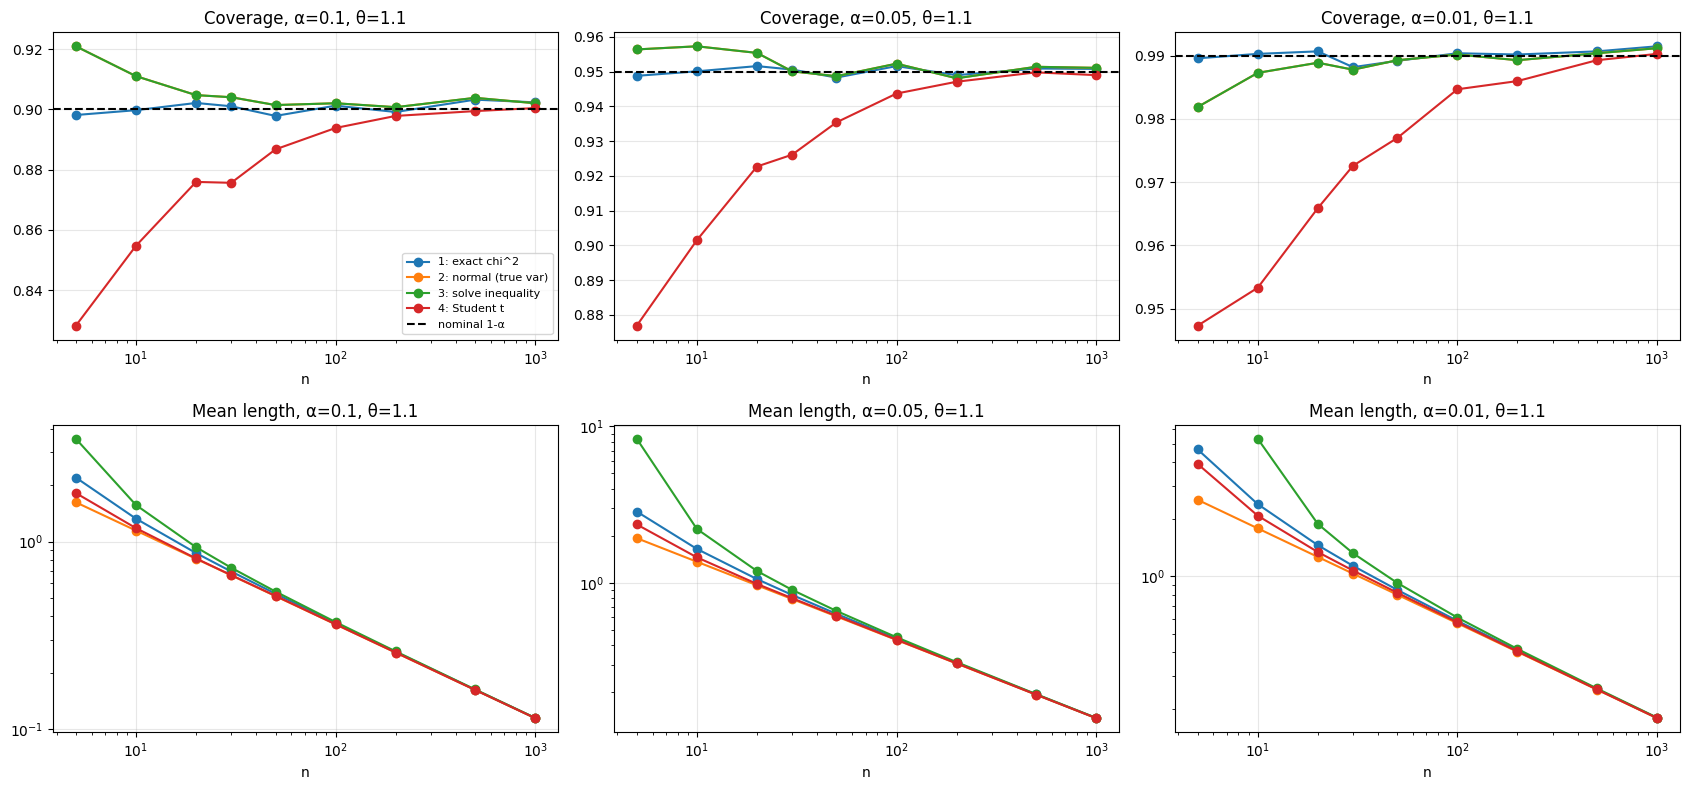


=== Effect of m (n=10, alpha=0.05, 20 repeated experiments per m) ===


mean     std     min     max
m      method                                              
100    1: exact chi^2        0.9515  0.0187  0.9000  0.9800
       2: normal (true var)  0.9625  0.0180  0.9200  0.9900
       3: solve inequality   0.9625  0.0180  0.9200  0.9900
       4: Student t          0.9025  0.0162  0.8800  0.9400
1000   1: exact chi^2        0.9512  0.0080  0.9330  0.9650
       2: normal (true var)  0.9568  0.0058  0.9380  0.9640
       3: solve inequality   0.9568  0.0058  0.9380  0.9640
       4: Student t          0.9008  0.0099  0.8830  0.9180
10000  1: exact chi^2        0.9502  0.0023  0.9451  0.9544
       2: normal (true var)  0.9550  0.0018  0.9516  0.9584
       3: solve inequality   0.9550  0.0018  0.9516  0.9584
       4: Student t          0.9005  0.0035  0.8945  0.9063
100000 1: exact chi^2        0.9503  0.0005  0.9494  0.9512
       2: normal (true var)  0.9551  0.0005  0.9542  0.9558
       3: solve inequality   0.9551  0.0005  0.9542  0.9558
       4: Student t          0.9003  0.0012  0.8984  0.9031

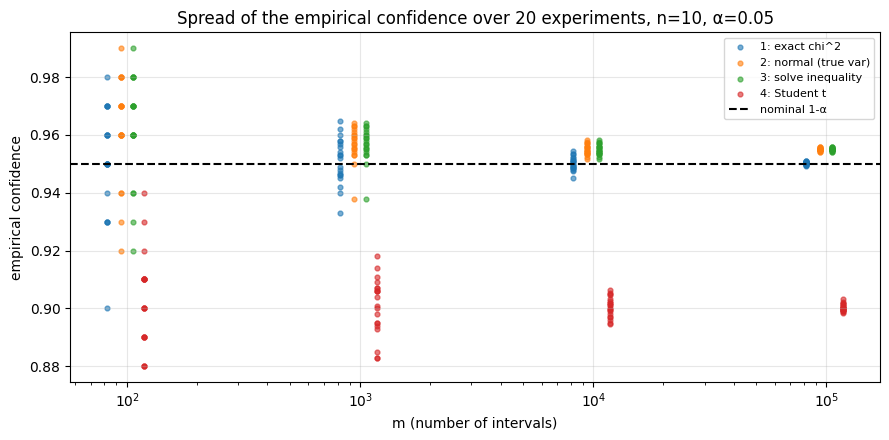

In [2]:
THETA1 = ID / 10                     # theta = 1/lambda = 1.1
ALPHAS1 = [0.1, 0.05, 0.01]
NS1 = [5, 10, 20, 30, 50, 100, 200, 500, 1000]
M1 = 10000
METHODS1 = ["1: exact chi^2", "2: normal (true var)", "3: solve inequality", "4: Student t"]

def exp_intervals(x, theta, alpha):
    """x: array (m, n) of exponential samples. Returns {method: (lo, hi)} with arrays of length m."""
    m, n = x.shape
    beta = 1 - alpha / 2
    z = stats.norm.ppf(beta)
    t = stats.t.ppf(beta, df=n - 1)
    chi_lo, chi_hi = stats.chi2.ppf([alpha / 2, beta], df=2 * n)
    xbar = x.mean(axis=1)
    s = x.std(axis=1, ddof=1)

    # Method 1: 2*n*xbar/theta ~ chi^2_{2n}
    lo1, hi1 = 2 * n * xbar / chi_hi, 2 * n * xbar / chi_lo
    # Method 2: uses the true theta in the standard deviation
    h2 = z * theta / np.sqrt(n)
    # Method 3: solve |theta - xbar| <= z*theta/sqrt(n) for theta
    lo3 = xbar / (1 + z / np.sqrt(n))
    hi3 = xbar / (1 - z / np.sqrt(n)) if z < np.sqrt(n) else np.full(m, np.inf)
    # Method 4: Student t with the sample standard deviation
    h4 = t * s / np.sqrt(n)

    return {
        METHODS1[0]: (lo1, hi1),
        METHODS1[1]: (xbar - h2, xbar + h2),
        METHODS1[2]: (lo3, hi3),
        METHODS1[3]: (xbar - h4, xbar + h4),
    }

def exact_coverage_23(n, alpha):
    """Exact P(|Z| <= z) for methods 2 and 3: n*xbar/theta ~ Gamma(n, 1)."""
    z = stats.norm.ppf(1 - alpha / 2)
    g = stats.gamma(a=n)
    return g.cdf(n + z * np.sqrt(n)) - g.cdf(max(n - z * np.sqrt(n), 0))

def simulate_exp(theta, ns, alphas, m):
    rows = []
    for n in ns:
        x = np.random.exponential(scale=theta, size=(m, n))
        for a in alphas:
            for meth, (lo, hi) in exp_intervals(x, theta, a).items():
                rows.append({
                    "n": n, "m": m, "alpha": a, "method": meth,
                    "coverage": np.mean((lo <= theta) & (theta <= hi)),
                    "length": np.mean(hi - lo),
                })
    return pd.DataFrame(rows)

# Main experiment: theta = ID/10, m = 10000, several n and alpha
df1 = simulate_exp(THETA1, NS1, ALPHAS1, M1)

for a in ALPHAS1:
    sub = df1[df1.alpha == a]
    cov = sub.pivot(index="n", columns="method", values="coverage")
    cov["exact (2, 3)"] = [exact_coverage_23(n, a) for n in cov.index]
    print(f"\n=== alpha = {a}  (nominal confidence {1 - a}) ===")
    print("--- empirical confidence (fraction of intervals containing theta) ---")
    display(cov.round(4))
    print("--- mean interval length ---")
    display(sub.pivot(index="n", columns="method", values="length").round(4))

# Plots: coverage and mean length vs n
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for j, a in enumerate(ALPHAS1):
    sub = df1[df1.alpha == a]
    for meth in METHODS1:
        d = sub[sub.method == meth]
        axes[0, j].plot(d.n, d.coverage, marker="o", label=meth)
        axes[1, j].plot(d.n, d.length.replace(np.inf, np.nan), marker="o", label=meth)
    axes[0, j].axhline(1 - a, color="k", ls="--", label="nominal 1-α")
    axes[0, j].set_title(f"Coverage, α={a}, θ={THETA1}")
    axes[1, j].set_title(f"Mean length, α={a}, θ={THETA1}")
    axes[1, j].set_yscale("log")
    for i in range(2):
        axes[i, j].set_xscale("log"); axes[i, j].set_xlabel("n"); axes[i, j].grid(alpha=.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Effect of m: n = 10, alpha = 0.05; 20 independent experiments for each m
M_LIST = [100, 1000, 10000, 100000]
N_M, A_M, REPS = 10, 0.05, 20
rows = []
for m in M_LIST:
    for r in range(REPS):
        d = simulate_exp(THETA1, [N_M], [A_M], m)
        d["rep"] = r
        rows.append(d)
df_m1 = pd.concat(rows)
summary_m = (df_m1.groupby(["m", "method"]).coverage
             .agg(["mean", "std", "min", "max"]).round(4))
print(f"\n=== Effect of m (n={N_M}, alpha={A_M}, {REPS} repeated experiments per m) ===")
display(summary_m)

fig, ax = plt.subplots(figsize=(9, 4.5))
for k, meth in enumerate(METHODS1):
    d = df_m1[df_m1.method == meth]
    ax.scatter(d.m * (1 + 0.12 * (k - 1.5)), d.coverage, s=12, alpha=.6, label=meth)
ax.axhline(1 - A_M, color="k", ls="--", label="nominal 1-α")
ax.set_xscale("log"); ax.set_xlabel("m (number of intervals)"); ax.set_ylabel("empirical confidence")
ax.set_title(f"Spread of the empirical confidence over {REPS} experiments, n={N_M}, α={A_M}")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

#### Conclusion

**(c) Effect of $n$ and $m$.**
- *Effect of $n$ on the confidence.* Method 1 is exact: its empirical confidence equals $1-\alpha$ for every $n$, even $n=5$, up to Monte Carlo noise. Methods 2–4 rely on the CLT, so their actual confidence differs from $1-\alpha$ for small $n$ and tends to $1-\alpha$ as $n$ grows.
  - Methods 2 and 3 have exactly the same coverage, as shown in (a). The simulated values agree with the exact $\Gamma(n,1)$ formula. For $n=5$ the coverage is $\approx 0.921$ instead of $0.90$ and $\approx 0.956$ instead of $0.95$, but $\approx 0.982$ instead of $0.99$. The error changes sign with $\alpha$ because $\overline{\mathbf X}$ is right-skewed, while the normal approximation is symmetric.
  - Method 4 **under-covers** for all small and moderate $n$, and this effect is the largest. For $n=5$ the coverage is $\approx 0.83 / 0.88 / 0.95$ instead of $0.90 / 0.95 / 0.99$, and even at $n=50$ it is $\approx 0.887 / 0.935 / 0.977$. The reason is the skewness of $\mathscr E(\lambda)$: $\overline{\mathbf X}$ and $S$ are positively correlated. A sample with small $\overline{\mathbf X}$ usually also has a small $S$, so exactly the intervals that lie too far left are also too short and miss $\theta$. Only for $n \gtrsim 200$ is the coverage within $\approx 0.005$ of nominal.
- *Effect of $n$ on the length.* All lengths decrease like $1/\sqrt n$; between $n=100$ and $n=1000$ they shrink by a factor of $\approx\sqrt{10}$. For large $n$ all four methods give practically the same interval: at $n=1000$, $\alpha=0.05$ all lengths are $\approx 0.137$. For small $n$ the lengths differ a lot, with $L_2 < L_4 < L_1 < L_3$. For example, at $n=5$, $\alpha=0.05$: $1.93,\ 2.36,\ 2.85,\ 8.33$. Interval 3 has the factor $1/(1-z_\beta^2/n)$, which explodes as $z_\beta^2 \to n$, and for $n=5$, $\alpha=0.01$ it is even infinite. Smaller $\alpha$ always gives longer intervals.
- *Effect of $m$.* $m$ does **not** change the true probability that $\theta$ lies in the interval. That probability is determined only by the method, $n$ and $\alpha$, and for methods 1–4 it does not depend on $\theta$ at all, because $\overline{\mathbf X}/\theta$ and $S/\theta$ have $\theta$-free distributions. $m$ only determines how precisely we *estimate* that probability. The empirical confidence is a binomial proportion with standard error $\sqrt{p(1-p)/m}$. For $p = 0.95$ this is $0.022,\ 0.007,\ 0.002,\ 0.0007$ for $m = 10^2, 10^3, 10^4, 10^5$, and it matches the observed spread over $20$ repeated experiments: $0.019,\ 0.008,\ 0.002,\ 0.0005$. With $m=100$ one cannot even tell method 1 from method 2. With $m \ge 10^4$ differences of $0.005$ become visible. $m$ also does not affect the lengths: the mean length only becomes a more precise estimate of $\mathsf E L$.

**(d) Comparison of the methods.**

| Method | Pros | Cons |
|---|---|---|
| 1: exact $\chi^2_{2n}$ | exact confidence $1-\alpha$ for **every** $n$; uses only $\overline{\mathbf X}$; never degenerates | needs the exact distribution of the statistic, i.e. works only for the exponential model; not symmetric around $\overline{\mathbf X}$ |
| 2: normal, known variance | shortest interval, deterministic length | depends on the unknown $\theta$, so it cannot be used in practice; only approximate for small $n$ |
| 3: solved inequality | does not depend on $\theta$; same coverage as method 2 (close to nominal already for $n \approx 20$) | longest interval for small $n$, infinite if $z_\beta \ge \sqrt n$; still only approximate; relies on the model $s^2=\theta^2$ |
| 4: Student $t$ | universal: works for any distribution with finite variance, no model for the variance needed | for skewed data like $\mathscr E(\lambda)$ it under-covers noticeably for small and moderate $n$; random length |

**Which is the best.**
- If the data are known to be exponential, **method 1** is the best for every $n$. It is the only method with guaranteed confidence $1-\alpha$, and for small $n$ it is much shorter than method 3, the only other practical method whose coverage is close to nominal for small $n$.
- Method 3 is a reasonable approximate alternative for moderate $n$ ($n \gtrsim 20$) when the variance is a known function of the mean.
- Method 4 is the choice when the distribution is unknown, but for skewed distributions it needs large samples ($n$ in the hundreds) to reach the nominal level.
- Method 2 is only a theoretical benchmark.
- For large $n$ ($n \gtrsim 500$) all four methods give practically the same intervals and the same coverage, so the choice does not matter.

---

### Problem 2

Repeat parts (2)–(4) of Problem 1 (with the corresponding amendments) for a Poisson distribution $\mathscr{P}(\theta)$.

The **Task** stays the same: derive the intervals, check that they contain the parameter $\theta$ with the prescribed probability, find their lengths, compare the methods and write your conclusions.

#### Solution

Let $X_1,\dots,X_n \sim \mathscr{P}(\theta)$ i.i.d. Then $\mathsf{E}X=\theta$ and $\mathrm{Var}\,X=\theta$, so $s^2=\theta$. Let $\beta = 1-\alpha/2$ and $z_\beta$ be the $\beta$-quantile of $\mathscr{N}(0,1)$.

**Method 2 (normal approximation, known variance).** By the CLT, $\overline{\mathbf X}\approx\mathscr N(\theta,\theta/n)$, so
$$Z=\frac{\sqrt n\,(\overline{\mathbf X}-\theta)}{\sqrt\theta}\approx \mathscr N(0,1),\qquad \mathsf P\big(|\theta-\overline{\mathbf X}|\le z_\beta\sqrt{\theta/n}\big)\approx 2\beta-1 = 1-\alpha.$$
Interval: $\;\overline{\mathbf X}\pm z_\beta\sqrt{\theta/n}$. It uses the unknown $\theta$, so it is not usable in practice; we still simulate it (with the true $\theta$) as a benchmark. Its length $2z_\beta\sqrt{\theta/n}$ is deterministic.

**Method 3 (solving the inequality for $\theta$).** Squaring $|\theta-\overline{\mathbf X}|\le z_\beta\sqrt{\theta/n}$ gives
$$\theta^2-\Big(2\overline{\mathbf X}+\frac{z_\beta^2}{n}\Big)\theta+\overline{\mathbf X}^2\le 0 .$$
The roots of the quadratic are
$$\theta_{1,2}=\overline{\mathbf X}+\frac{z_\beta^2}{2n}\pm z_\beta\sqrt{\frac{\overline{\mathbf X}}{n}+\frac{z_\beta^2}{4n^2}},$$
and the interval is $[\theta_1,\theta_2]$. It does not depend on the unknown parameter. Its length is $2z_\beta\sqrt{\overline{\mathbf X}/n+z_\beta^2/(4n^2)}$ (random).

**Method 4 (Student $t$).** Estimate $s$ by $S=\sqrt{\frac1{n-1}\sum(X_i-\overline{\mathbf X})^2}$ and use $T=\sqrt n(\overline{\mathbf X}-\theta)/S\approx t_{n-1}$:
$$\overline{\mathbf X}\pm t_{n-1,\beta}\frac{S}{\sqrt n}.$$
Note: if all $X_i=0$ then $\overline{\mathbf X}=S=0$ and the interval degenerates to a point.

**Simulation plan.** For every $n$ and $\alpha\in\{0.1,0.05,0.01\}$ we generate $m$ samples with `np.random.poisson`, build the three intervals for each sample, and compute (i) the empirical confidence = fraction of intervals containing $\theta$ and (ii) the mean interval length. The standard error of an empirical confidence $\hat p$ is $\sqrt{\hat p(1-\hat p)/m}$, so $m$ controls only the precision of the estimate, while $n$ controls the quality of the approximation. We use $\theta=\texttt{ID}/10=1.1$ and also larger $\theta$ to see the effect of the Poisson mean.


=== alpha = 0.1  (nominal confidence 0.9) ===
method  2: normal (true var)  3: solve inequality  4: Student t
n                                                              
5                     0.9177               0.9177        0.8991
10                    0.9085               0.9085        0.8768
20                    0.8950               0.8950        0.8949
50                    0.9118               0.9118        0.8985
100                   0.9013               0.9013        0.8927
200                   0.9057               0.9057        0.9032
500                   0.9017               0.9017        0.9009
1000                  0.9033               0.9033        0.9016
--- mean length ---
method  2: normal (true var)  3: solve inequality  4: Student t
n                                                              
5                     1.5430               1.6090        1.8558
10                    1.0911               1.1105        1.1701
20                    0.7715         

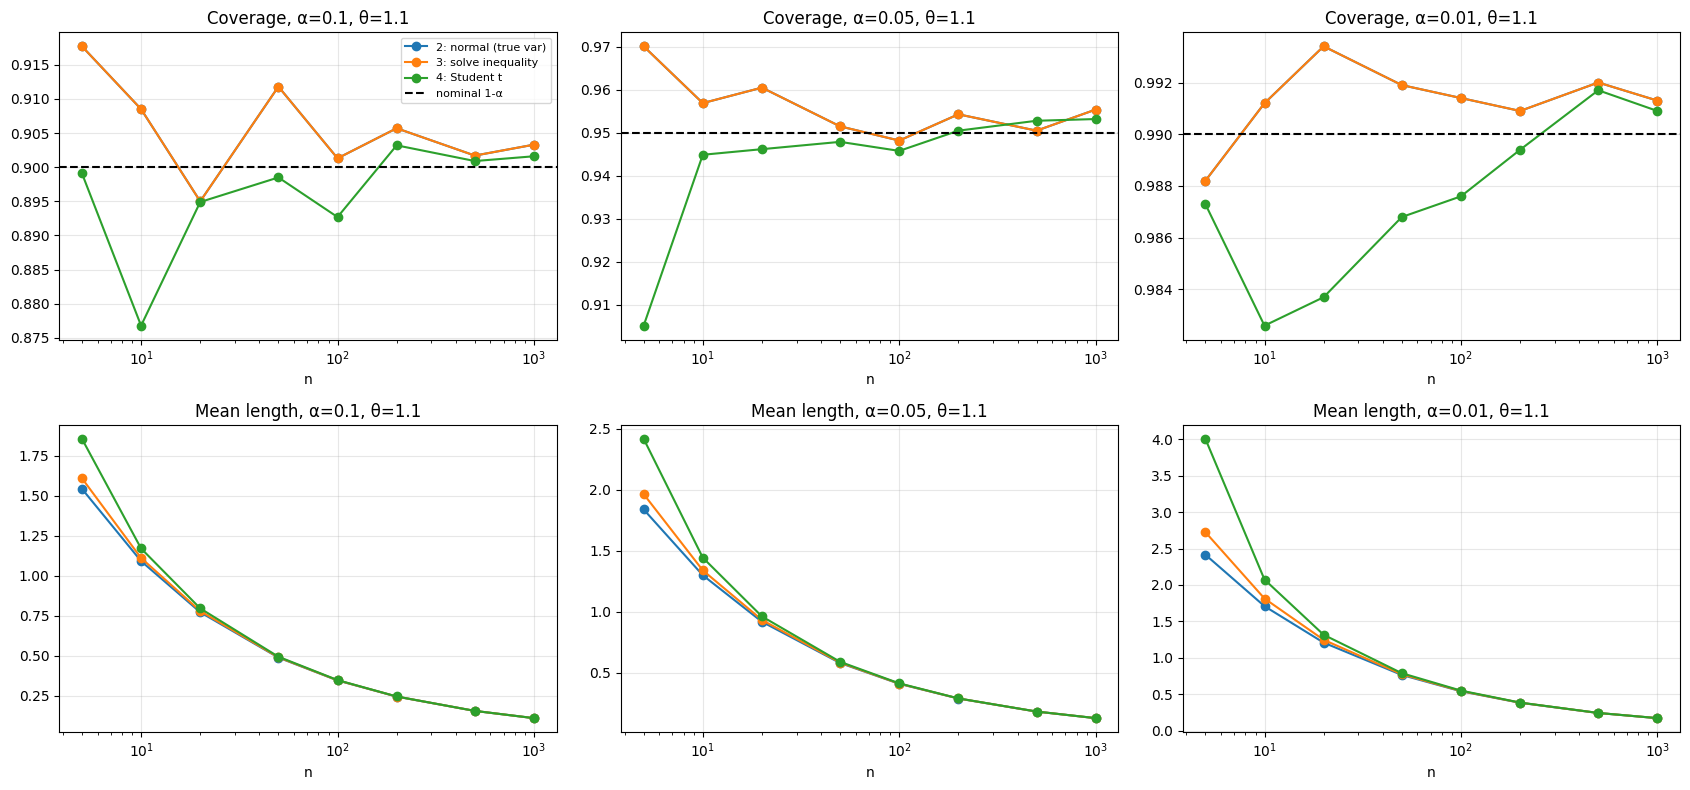


=== Effect of m (n=50, alpha=0.05) ===
method  2: normal (true var)  3: solve inequality  4: Student t
m                                                              
100                   0.9300               0.9300        0.9400
1000                  0.9530               0.9530        0.9540
10000                 0.9526               0.9526        0.9483
100000                0.9496               0.9496        0.9455


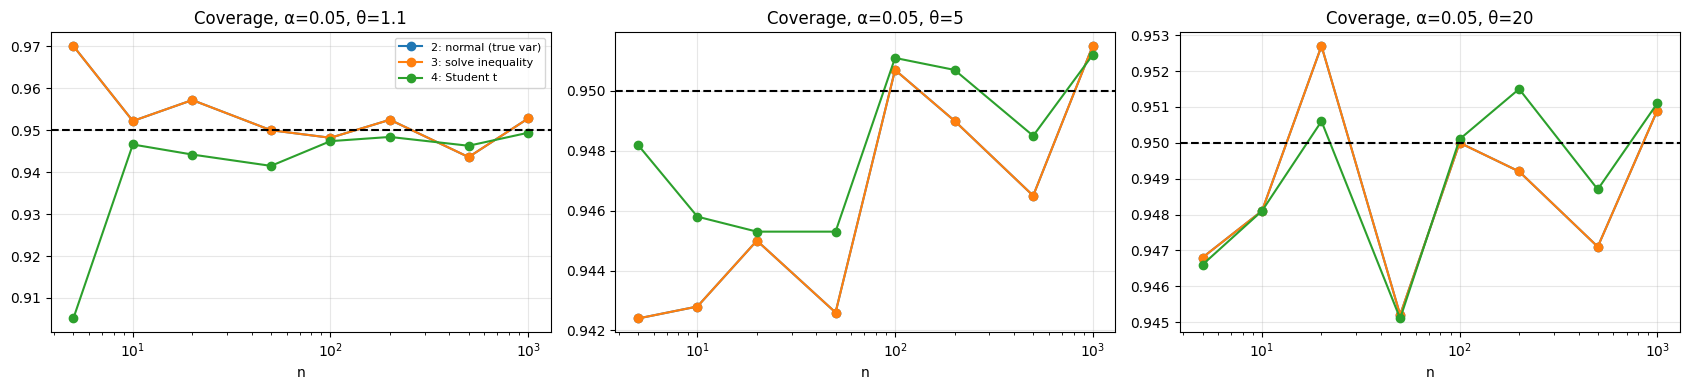

In [3]:
THETA = ID / 10                      # 1.1
ALPHAS = [0.1, 0.05, 0.01]
NS = [5, 10, 20, 50, 100, 200, 500, 1000]
M = 10000
METHODS = ["2: normal (true var)", "3: solve inequality", "4: Student t"]

def poisson_intervals(x, theta, alpha):
    """x: array (m, n) of Poisson samples. Returns {method: (lo, hi)} with arrays of length m."""
    m, n = x.shape
    beta = 1 - alpha / 2
    z = stats.norm.ppf(beta)
    t = stats.t.ppf(beta, df=n - 1)
    xbar = x.mean(axis=1)
    s = x.std(axis=1, ddof=1)

    # Method 2: uses the true theta in the variance
    h2 = z * np.sqrt(theta / n)
    # Method 3: roots of the quadratic inequality
    centre3 = xbar + z**2 / (2 * n)
    h3 = z * np.sqrt(xbar / n + z**2 / (4 * n**2))
    # Method 4: Student t with sample std
    h4 = t * s / np.sqrt(n)

    return {
        METHODS[0]: (xbar - h2, xbar + h2),
        METHODS[1]: (centre3 - h3, centre3 + h3),
        METHODS[2]: (xbar - h4, xbar + h4),
    }

def simulate(theta, ns, alphas, m):
    rows = []
    for n in ns:
        x = np.random.poisson(lam=theta, size=(m, n))
        for a in alphas:
            for meth, (lo, hi) in poisson_intervals(x, theta, a).items():
                rows.append({
                    "theta": theta, "n": n, "m": m, "alpha": a, "method": meth,
                    "coverage": np.mean((lo <= theta) & (theta <= hi)),
                    "length": np.mean(hi - lo),
                })
    return pd.DataFrame(rows)

# Main experiment: theta = ID/10
df_main = simulate(THETA, NS, ALPHAS, M)

for a in ALPHAS:
    print(f"\n=== alpha = {a}  (nominal confidence {1-a}) ===")
    print(df_main[df_main.alpha == a]
          .pivot(index="n", columns="method", values="coverage").round(4))
    print("--- mean length ---")
    print(df_main[df_main.alpha == a]
          .pivot(index="n", columns="method", values="length").round(4))

# Plots: coverage and length vs n
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for j, a in enumerate(ALPHAS):
    sub = df_main[df_main.alpha == a]
    for meth in METHODS:
        d = sub[sub.method == meth]
        axes[0, j].plot(d.n, d.coverage, marker="o", label=meth)
        axes[1, j].plot(d.n, d.length, marker="o", label=meth)
    axes[0, j].axhline(1 - a, color="k", ls="--", label="nominal 1-α")
    axes[0, j].set_title(f"Coverage, α={a}, θ={THETA}")
    axes[1, j].set_title(f"Mean length, α={a}, θ={THETA}")
    for i in range(2):
        axes[i, j].set_xscale("log"); axes[i, j].set_xlabel("n"); axes[i, j].grid(alpha=.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Effect of m (fixed n = 50, alpha = 0.05)
rows = []
for m in [100, 1000, 10000, 100000]:
    d = simulate(THETA, [50], [0.05], m)
    rows.append(d)
df_m = pd.concat(rows)
print("\n=== Effect of m (n=50, alpha=0.05) ===")
print(df_m.pivot(index="m", columns="method", values="coverage").round(4))

# Effect of theta (alpha = 0.05)
df_theta = pd.concat([simulate(th, NS, [0.05], M) for th in [THETA, 5, 20]])
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, th in zip(axes, [THETA, 5, 20]):
    sub = df_theta[df_theta.theta == th]
    for meth in METHODS:
        d = sub[sub.method == meth]
        ax.plot(d.n, d.coverage, marker="o", label=meth)
    ax.axhline(0.95, color="k", ls="--")
    ax.set_xscale("log"); ax.set_title(f"Coverage, α=0.05, θ={th}")
    ax.set_xlabel("n"); ax.grid(alpha=.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Conclusion

- **Effect of $n$.** As $n$ grows, the empirical confidence of all three methods approaches the nominal $1-\alpha$ and the interval length shrinks like $1/\sqrt n$. For small $n$ and $\theta=1.1$ the coverage is not smooth: the Poisson law is discrete and skewed, so methods 2 and 3 over-cover, while method 4 under-covers noticeably.
- **Effect of $m$.** $m$ does not change the true coverage probability, it only reduces the noise of its estimate (standard error $\sqrt{\hat p(1-\hat p)/m}\approx 0.002$ for $m=10^4$). For $m=100$ the estimates are very noisy, for $m\ge10^4$ they are stable.
- **Effect of $\alpha$.** Smaller $\alpha$ gives longer intervals (larger $z_\beta$). For small $n$ the deviation of the coverage from $1-\alpha$ is not monotone in $\alpha$ (for $n=5$, $\theta=1.1$ it is about $0.018$ for $\alpha=0.1$, $0.020$ for $\alpha=0.05$ and close to $0$ for $\alpha=0.01$), because the coverage of a discrete distribution depends on where the interval endpoints fall relative to the integer-valued sample sums.
- **Effect of $\theta$.** For $\theta=5$ and $\theta=20$ the coverage of all methods stays within about $0.01$ of $0.95$ already for small $n$. The remaining zigzag comes from the discreteness of the Poisson distribution (the sample sum is integer-valued, so coverage jumps with $n$) and from Monte Carlo noise. For small $\theta n$ the samples contain only a few distinct values; all-zero samples are rare, though (their probability is $e^{-\theta n}\approx 0.004$ for $\theta=1.1$, $n=5$).
- **Methods 2 and 3 have identical coverage.** Squaring $|\theta-\overline{\mathbf X}|\le z_\beta\sqrt{\theta/n}$ is an equivalent transformation, so on the same samples the events "$\theta\in$ interval 2" and "$\theta\in$ interval 3" coincide. They differ only in length: $L_2<L_3<L_4$ for small $n$, and all three merge for large $n$.
- **Comparison.** Method 2 needs the unknown $\theta$ and is only a benchmark. Method 3 uses only $\overline{\mathbf X}$ and never degenerates (for $\overline{\mathbf X}=0$ it gives $[0,z_\beta^2/n]$), but relies on the Poisson variance formula $s^2=\theta$. Method 4 is universal (no distribution-specific variance is needed), but for small $\theta n$ the estimate $S$ is unreliable (and the interval even collapses to a point when all $X_i=0$), which gives the worst coverage.
- **Best method:** method 3 for small $n$ / small $\theta$ when the data are known to be Poisson; method 4 when the variance model is unknown and $n$ is large; for large $n$ all methods are practically equivalent.

---

## Part II: Unbiasedness of Estimators

### Problem 3

In this task you need to analyze the estimators of the variance and their properties: we will prove the unbiasedness of the variance estimator theoretically and check it in practice!

There are two common estimators of the population variance:
$$
\sigma^2_n = \frac{1}{n}\sum_{i=1}^{n}(X_i - \overline{X})^2,
\qquad
\sigma^2_{n-1} = \frac{1}{n-1}\sum_{i=1}^{n}(X_i - \overline{X})^2.
$$

**Task:**

**(a)** Write code to generate a dataset of i.i.d. samples from $\mathcal{N}(\mu, \sigma^2)$ with $\mu = \texttt{ID}$ and $\sigma^2 = (\texttt{ID} \bmod 5) + 2$, and find the variance of the dataset.

**(b)** Find $\sigma^2_n$ and $\sigma^2_{n-1}$ for $n = 10$, $n = 50$, $n = 100$, $n = 1000$.

**(c)** Find the biases $Bias(\sigma^2_n) = E(\sigma^2_n) - \sigma^2$ and $Bias(\sigma^2_{n-1}) = E(\sigma^2_{n-1}) - \sigma^2$ (estimate the expectations by averaging over many simulated datasets).

**(d)** Comment on the results for the different values of $n$.

**(e)** Derive analytically the expected value of each estimator, $E(\sigma^2_n)$ and $E(\sigma^2_{n-1})$.

**(f)** Using the expected values found above, show mathematically which of the two estimators is unbiased.

**(g)** Comment on the results of the theoretical and practical tasks.

#### Solution

**Parameters.** $\mu = \texttt{ID} = 11$, $\sigma^2 = (11 \bmod 5) + 2 = 3$. Parts (a)–(c) are computed in the code cell below; here we derive parts (e) and (f) analytically.

**(e) Expected values of the estimators.**

Let $X_1, \dots, X_n$ be i.i.d. with $E(X_i) = \mu$ and $Var(X_i) = \sigma^2$, and denote
$$
S := \sum_{i=1}^{n}(X_i - \overline{X})^2 .
$$

*Step 1: rewrite $S$ through deviations from $\mu$.* Write $X_i - \overline{X} = (X_i - \mu) - (\overline{X} - \mu)$ and square:
$$
S = \sum_{i=1}^{n}(X_i - \mu)^2 - 2(\overline{X} - \mu)\sum_{i=1}^{n}(X_i - \mu) + n(\overline{X} - \mu)^2 .
$$
Since $\sum_{i=1}^{n}(X_i - \mu) = n\overline{X} - n\mu = n(\overline{X} - \mu)$, the middle term equals $-2n(\overline{X} - \mu)^2$, so
$$
S = \sum_{i=1}^{n}(X_i - \mu)^2 - n(\overline{X} - \mu)^2 .
$$

*Step 2: take expectations.* By definition of variance, $E\big[(X_i - \mu)^2\big] = Var(X_i) = \sigma^2$.
Since $E(\overline{X}) = \mu$, we have $E\big[(\overline{X} - \mu)^2\big] = Var(\overline{X})$, and by independence of $X_i$
$$
Var(\overline{X}) = Var\Big(\frac{1}{n}\sum_{i=1}^{n} X_i\Big) = \frac{1}{n^2}\sum_{i=1}^{n} Var(X_i) = \frac{1}{n^2}\cdot n\sigma^2 = \frac{\sigma^2}{n}.
$$
Therefore
$$
E(S) = n\sigma^2 - n\cdot\frac{\sigma^2}{n} = (n-1)\,\sigma^2 .
$$

*Step 3: expectations of the estimators.* Since $\sigma^2_n = S/n$ and $\sigma^2_{n-1} = S/(n-1)$,
$$
E(\sigma^2_n) = \frac{n-1}{n}\,\sigma^2,
\qquad
E(\sigma^2_{n-1}) = \frac{n-1}{n-1}\,\sigma^2 = \sigma^2 .
$$

**(f) Which estimator is unbiased.**
$$
Bias(\sigma^2_n) = E(\sigma^2_n) - \sigma^2 = \frac{n-1}{n}\sigma^2 - \sigma^2 = -\frac{\sigma^2}{n} \neq 0,
$$
$$
Bias(\sigma^2_{n-1}) = E(\sigma^2_{n-1}) - \sigma^2 = \sigma^2 - \sigma^2 = 0 .
$$
Hence $\sigma^2_{n-1}$ is an **unbiased** estimator of $\sigma^2$, while $\sigma^2_n$ is **biased**: on average it underestimates $\sigma^2$ by $\sigma^2/n$. The bias tends to $0$ as $n \to \infty$, so $\sigma^2_n$ is only *asymptotically* unbiased.

The reason for the bias is that the deviations are measured from $\overline{X}$, not from the true $\mu$. The sample mean is, by construction, the point closest to the data, so $\sum (X_i - \overline{X})^2$ is on average smaller than $\sum (X_i - \mu)^2$ by exactly $n\,Var(\overline{X}) = \sigma^2$. Dividing by $n-1$ instead of $n$ compensates for this.

For our parameters ($\sigma^2 = 3$) the theoretical bias $-\sigma^2/n$ equals:

| $n$ | 10 | 50 | 100 | 1000 |
|---|---|---|---|---|
| $Bias(\sigma^2_n) = -3/n$ | $-0.3$ | $-0.06$ | $-0.03$ | $-0.003$ |
| $Bias(\sigma^2_{n-1})$ | $0$ | $0$ | $0$ | $0$ |

(a) mu = 11, true sigma^2 = 3
    dataset of size 1000: sample mean = 11.0358, variance of the dataset = 3.0405

(b) Estimators computed on a single sample:


,sigma2_n (1/n),sigma2_{n-1} (1/(n-1))
n,,
10,2.3977,2.6641
50,3.8839,3.9632
100,3.5004,3.5358
1000,3.0405,3.0436


(c) Expectations and biases (averaged over 10000 datasets):


,E[sigma2_n],Bias(sigma2_n),theoretical bias -sigma2/n,E[sigma2_{n-1}],Bias(sigma2_{n-1})
n,,,,,
10,2.6912,-0.3088,-0.300,2.9902,-0.0098
50,2.9496,-0.0504,-0.060,3.0098,0.0098
100,2.9726,-0.0274,-0.030,3.0026,0.0026
1000,2.9981,-0.0019,-0.003,3.0011,0.0011


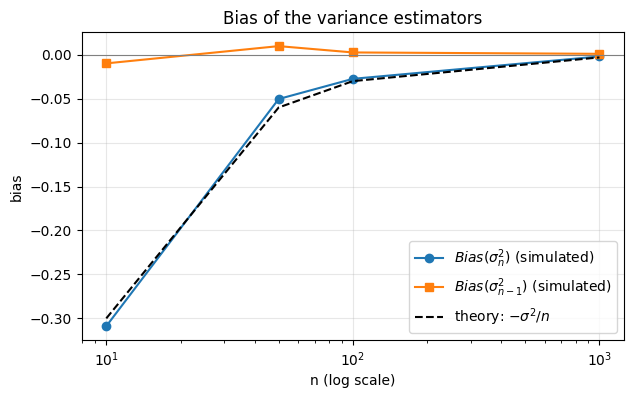

In [4]:
MU = ID
SIGMA2 = (ID % 5) + 2
SIGMA = np.sqrt(SIGMA2)
N_LIST = [10, 50, 100, 1000]
M_REP = 10_000

# (a) one dataset of i.i.d. N(MU, SIGMA2) samples and its variance
N_DATA = 1000
data = np.random.normal(loc=MU, scale=SIGMA, size=N_DATA)
print(f"(a) mu = {MU}, true sigma^2 = {SIGMA2}")
print(f"    dataset of size {N_DATA}: sample mean = {data.mean():.4f}, "
      f"variance of the dataset = {np.var(data, ddof=0):.4f}\n")

# (b) both estimators on one sample of size n (first n values of the dataset)
rows_b = []
for n in N_LIST:
    x = data[:n]
    rows_b.append({"n": n,
                   "sigma2_n  (1/n)": np.var(x, ddof=0),
                   "sigma2_{n-1}  (1/(n-1))": np.var(x, ddof=1)})
table_b = pd.DataFrame(rows_b).set_index("n")
print("(b) Estimators computed on a single sample:")
display(table_b.round(4))

# (c) biases: average each estimator over M_REP independent datasets of size n
rows_c = []
for n in N_LIST:
    samples = np.random.normal(loc=MU, scale=SIGMA, size=(M_REP, n))
    s2_n  = samples.var(axis=1, ddof=0)
    s2_n1 = samples.var(axis=1, ddof=1)
    rows_c.append({"n": n,
                   "E[sigma2_n]": s2_n.mean(),
                   "Bias(sigma2_n)": s2_n.mean() - SIGMA2,
                   "theoretical bias  -sigma2/n": -SIGMA2 / n,
                   "E[sigma2_{n-1}]": s2_n1.mean(),
                   "Bias(sigma2_{n-1})": s2_n1.mean() - SIGMA2})
table_c = pd.DataFrame(rows_c).set_index("n")
print(f"(c) Expectations and biases (averaged over {M_REP} datasets):")
display(table_c.round(4))

# plot: bias vs n
plt.figure(figsize=(7, 4))
plt.plot(N_LIST, table_c["Bias(sigma2_n)"], "o-", label=r"$Bias(\sigma^2_n)$ (simulated)")
plt.plot(N_LIST, table_c["Bias(sigma2_{n-1})"], "s-", label=r"$Bias(\sigma^2_{n-1})$ (simulated)")
plt.plot(N_LIST, -SIGMA2 / np.array(N_LIST), "k--", label=r"theory: $-\sigma^2/n$")
plt.axhline(0, color="gray", lw=0.8)
plt.xscale("log")
plt.xlabel("n (log scale)")
plt.ylabel("bias")
plt.title("Bias of the variance estimators")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Conclusion

**(a)** The variance of the generated dataset of $1000$ values from $\mathcal{N}(11, 3)$ is close to the true $\sigma^2 = 3$, and the sample mean is close to $\mu = 11$, so the data are generated correctly.

**(d) Results for different $n$.**
- *Single sample (part b).* For one sample the estimates fluctuate noticeably around $3$, especially for small $n$; this is random sampling error, not bias, and it decreases as $n$ grows (at $n = 1000$ both estimates are very close to $3$). On the same sample the two estimators differ only by the factor $\frac{n}{n-1}$: at $n = 10$ this is $10/9 \approx 1.11$ (a visible difference), while at $n = 1000$ it is $1.001$ and the estimators practically coincide.
- *Averaged over $10\,000$ datasets (part c).* The average of $\sigma^2_n$ is systematically below $3$: the simulated bias is $\approx -0.31$ for $n = 10$, $\approx -0.05$ for $n = 50$, $\approx -0.03$ for $n = 100$ and $\approx -0.002$ for $n = 1000$. The bias of $\sigma^2_{n-1}$ is close to $0$ for every $n$ (its deviations from zero are of the order of the Monte Carlo error and have no fixed sign).
- So the bias of $\sigma^2_n$ is significant for small samples and becomes negligible for large $n$; $\sigma^2_{n-1}$ is accurate on average for all $n$.

**(g) Theory vs. practice.** The simulated biases agree with the analytical result $Bias(\sigma^2_n) = -\sigma^2/n$ from part (e)–(f): on the plot, the simulated curve for $\sigma^2_n$ lies on the theoretical line $-\sigma^2/n$, and the curve for $\sigma^2_{n-1}$ stays at $0$. Small remaining differences are due to the finite number of simulated datasets and shrink as it grows. Both theory and simulation show that $\sigma^2_{n-1}$ is the unbiased estimator of the variance, while $\sigma^2_n$ underestimates it by $\sigma^2/n$; for small samples one should therefore use $\sigma^2_{n-1}$, and for large $n$ the difference between them is negligible.